# rel-hm / item-sales — Features de nœuds enrichies

> **Variante de `hm_gnn.ipynb`** : les features de nœuds sont reconstruites :
> - articles : on garde 2 catégorielles haut-niveau + 4 lags + 5 **comportementales** (popularité, fidélité, tendance…)
> - customers : on garde âge + club_status + 5 **comportementales** (récence, fréquence, panier…)
> - Les catégorielles bruyantes (product_type, colour, dept…) et fashion_news_frequency sont supprimées.

Runs : 0 saut vs 2 sauts × 3 seeds → est-ce que les features comportementales
rendent la propagation graphe plus utile ?


In [1]:
#!pip install torch torch_geometric relbench -q

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
import pandas as pd, numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from relbench.tasks import get_task

print(f"PyTorch : {torch.__version__}")
import torch_geometric; print(f"PyG     : {torch_geometric.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {device}")

PyTorch : 2.7.1+cu118
PyG     : 2.8.0
Device  : cuda


## 1. Chargement des données

In [3]:
print("Chargement rel-hm...")
task = get_task('rel-hm', 'item-sales', download=False)
db   = task.dataset.get_db()

articles_df      = db.table_dict['article'].df.copy()
customers_df     = db.table_dict['customer'].df.copy()
transactions_df  = db.table_dict['transactions'].df.copy()

train_tbl = task.get_table("train")
val_tbl   = task.get_table("val")
test_tbl  = task.get_table("test")

VAL_TIMESTAMP  = val_tbl.df['timestamp'].iloc[0]
TEST_TIMESTAMP = test_tbl.df['timestamp'].iloc[0]

print(f"Articles     : {len(articles_df):,}")
print(f"Customers    : {len(customers_df):,}")
print(f"Transactions : {len(transactions_df):,}")
print(f"Val  : {VAL_TIMESTAMP.date()} | Test : {TEST_TIMESTAMP.date()}")

Chargement rel-hm...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...


Done in 2.25 seconds.


Articles     : 105,542
Customers    : 1,371,980
Transactions : 15,187,287
Val  : 2020-09-07 | Test : 2020-09-14


## 2. Encodage des nœuds

In [4]:
import numpy as np, pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# ── Transactions train uniquement (aucune fuite vers la val) ─────────────────
_tx = transactions_df[transactions_df['t_dat'] < VAL_TIMESTAMP].copy()
_tx['week'] = _tx['t_dat'].dt.to_period('W')

# ============================================================
# ARTICLES
# ============================================================

art_map = {aid: i for i, aid in enumerate(articles_df['article_id'].values)}
N_ART   = len(art_map)
_art_ids = articles_df['article_id'].values   # ordre canonique

# -- 1. Features originales retenues : index_group_name, product_group_name
#    (niveaux haut de la hiérarchie produit, ~6 et ~21 valeurs)
#    Supprimées : product_type (132 val), colour_group, department, garment_group
#    -> trop granulaires, correlation quasi nulle avec les ventes, bruit dans message passing
_enc_art = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
_art_orig = _enc_art.fit_transform(
    articles_df[['index_group_name', 'product_group_name']].fillna('missing').astype(str)
).astype(np.float32)
_art_orig = (_art_orig - _art_orig.mean(0)) / (_art_orig.std(0) + 1e-8)  # [N_art, 2]

# -- 2. Features historiques déjà créées (lag1, rec4, hmean, hmax) -- inchangées
_panel = train_tbl.df
_weeks = np.sort(_panel['timestamp'].unique())
_lag1  = _panel[_panel['timestamp'] == _weeks[-1]].set_index('article_id')['sales']
_rec4  = _panel[_panel['timestamp'].isin(_weeks[-4:])].groupby('article_id')['sales'].mean()
_hmean = _panel.groupby('article_id')['sales'].mean()
_hmax  = _panel.groupby('article_id')['sales'].max()

_art_hist = np.zeros((N_ART, 4), dtype=np.float32)
for j, s in enumerate([_lag1, _rec4, _hmean, _hmax]):
    idx = np.fromiter((art_map[a] for a in s.index), dtype=np.int64, count=len(s))
    _art_hist[idx, j] = np.log1p(s.values.astype(np.float32))
_art_hist = (_art_hist - _art_hist.mean(0)) / (_art_hist.std(0) + 1e-8)  # [N_art, 4]

# -- 3. Nouvelles features comportementales article (depuis _tx) ──────────────
# n_distinct_buyers : popularité absolue (combien de clients différents ont acheté)
_n_buyers = _tx.groupby('article_id')['customer_id'].nunique()

# repeat_rate : fraction d'acheteurs ayant racheté au moins une fois -> fidélité au produit
_tx_cnt = _tx.groupby(['article_id', 'customer_id']).size().reset_index(name='n')
_repeat  = _tx_cnt.groupby('article_id')['n'].apply(lambda x: float((x > 1).mean()))

# n_weeks_with_sales : nombre de semaines avec ventes > 0 -> régularité vs one-hit
_n_wk_sales = _tx.groupby('article_id')['week'].nunique()

# sales_trend : moyenne dernières 4 semaines - moyenne 4 semaines précédentes
#   positif = croissance, négatif = déclin
_wk_sales = _tx.groupby(['article_id', 'week']).size().reset_index(name='s')
_all_wk   = sorted(_tx['week'].unique())
_last4 = set(_all_wk[-4:])
_prev4 = set(_all_wk[-8:-4]) if len(_all_wk) >= 8 else set(_all_wk[:-4])
_recent_m = _wk_sales[_wk_sales['week'].isin(_last4)].groupby('article_id')['s'].mean()
_prev_m   = _wk_sales[_wk_sales['week'].isin(_prev4)].groupby('article_id')['s'].mean()
_trend    = (_recent_m - _prev_m).fillna(0.0)

# sales_cv : coefficient de variation (std/mean) des ventes hebdo -> stable vs erratique
_art_cv = _wk_sales.groupby('article_id')['s'].agg(['mean', 'std']).fillna(0)
_art_cv['cv'] = _art_cv['std'] / (_art_cv['mean'] + 1e-8)

# Assemblage [N_art, 5] — log1p sur les grandes valeurs, standardisation finale
_art_behav = np.zeros((N_ART, 5), dtype=np.float32)
_behav_specs = [
    (_n_buyers,       True),    # log1p : distribution très skewée
    (_repeat,         False),
    (_n_wk_sales,     True),    # log1p
    (_trend,          False),   # peut etre negatif
    (_art_cv['cv'],   False),
]
for i, (series, do_log) in enumerate(_behav_specs):
    vals = series.reindex(_art_ids).fillna(0).values.astype(np.float32)
    _art_behav[:, i] = np.log1p(vals) if do_log else vals
_art_behav = (_art_behav - _art_behav.mean(0)) / (_art_behav.std(0) + 1e-8)  # [N_art, 5]

# -- Assemblage final article : [2 orig | 4 hist | 5 behav] = 11 dims ─────────
art_feat = torch.tensor(
    np.hstack([_art_orig, _art_hist, _art_behav]), dtype=torch.float32)
art_feat_nohist = torch.tensor(
    np.hstack([_art_orig, _art_behav]), dtype=torch.float32)
assert torch.isfinite(art_feat).all(), 'art_feat NaN/inf'

# ============================================================
# CUSTOMERS
# ============================================================

cust_map  = {cid: i for i, cid in enumerate(customers_df['customer_id'].values)}
N_CUST    = len(cust_map)
_cust_ids = customers_df['customer_id'].values

# -- 1. Features originales retenues : age, club_member_status
#    Supprimée : fashion_news_frequency (corrélée au statut club, bruit supplémentaire)
_enc_club = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
_cust_club = _enc_club.fit_transform(
    customers_df[['club_member_status']].fillna('missing').astype(str)
).astype(np.float32)
_cust_club = (_cust_club - _cust_club.mean(0)) / (_cust_club.std(0) + 1e-8)  # [N_cust, 1]

_cust_age = customers_df['age'].fillna(customers_df['age'].median()).values.reshape(-1,1).astype(np.float32)
_cust_age = (_cust_age - _cust_age.mean()) / (_cust_age.std() + 1e-8)         # [N_cust, 1]

# -- 2. Nouvelles features comportementales customer (depuis _tx) ─────────────
# recency : semaines depuis le dernier achat avant val (inactif = grande valeur)
_last_tx  = _tx.groupby('customer_id')['t_dat'].max()
_recency  = (VAL_TIMESTAMP - _last_tx).dt.days / 7.0

# n_purchases : volume total d'achats (log1p)
_n_purch = _tx.groupby('customer_id').size()

# n_unique_articles : largeur du panier (diversité) (log1p)
_n_uniq = _tx.groupby('customer_id')['article_id'].nunique()

# frequency : achats par semaine active (entre premier et dernier achat)
_first_tx = _tx.groupby('customer_id')['t_dat'].min()
_active_wk = ((_last_tx - _first_tx).dt.days / 7.0 + 1.0).clip(lower=1.0)
_freq = _n_purch / _active_wk

# session_size : nombre moyen d'articles par jour d'achat
_sessions  = _tx.groupby(['customer_id', 't_dat']).size().reset_index(name='n')
_sess_size = _sessions.groupby('customer_id')['n'].mean()

# Assemblage [N_cust, 5]
_max_rec = float(_recency.max()) if len(_recency) > 0 else 52.0
_cust_behav = np.zeros((N_CUST, 5), dtype=np.float32)
_cbehav_specs = [
    # clients sans transaction -> recence max (inactifs), autres -> 0
    (_recency,   False, _max_rec + 4),   # fillna = inactif
    (_n_purch,   True,  0.0),
    (_n_uniq,    True,  0.0),
    (_freq,      False, 0.0),
    (_sess_size, False, 0.0),
]
for i, (series, do_log, fill) in enumerate(_cbehav_specs):
    vals = series.reindex(_cust_ids).fillna(fill).values.astype(np.float32)
    _cust_behav[:, i] = np.log1p(vals) if do_log else vals
_cust_behav = (_cust_behav - _cust_behav.mean(0)) / (_cust_behav.std(0) + 1e-8)  # [N_cust, 5]

# -- Assemblage final customer : [club | age | 5 behav] = 7 dims ─────────────
cust_feat = torch.tensor(
    np.hstack([_cust_club, _cust_age, _cust_behav]), dtype=torch.float32)
assert torch.isfinite(cust_feat).all(), 'cust_feat NaN/inf'

print(f"Article  features : {tuple(art_feat.shape)}  "
      f"(2 orig + 4 hist + 5 behav : n_buyers/repeat/n_wk/trend/cv)")
print(f"Customer features : {tuple(cust_feat.shape)}  "
      f"(2 orig : age/club + 5 behav : recence/n_purch/n_uniq/freq/session)")


Article  features : (105542, 11)  (2 orig + 4 hist + 5 behav : n_buyers/repeat/n_wk/trend/cv)
Customer features : (1371980, 7)  (2 orig : age/club + 5 behav : recence/n_purch/n_uniq/freq/session)


## 3. Construction du graphe (transactions de la période train uniquement)

In [5]:
# Transactions avant VAL_TIMESTAMP uniquement (pas de fuite)
tx_train = transactions_df[transactions_df['t_dat'] < VAL_TIMESTAMP].copy()
print(f"Transactions train : {len(tx_train):,}")

# Agrégation → arêtes uniques (customer, article), AVANT sparsification.
# On garde edges_full intact : la sparsification (et son aléa) est déplacée dans
# build_graph() pour pouvoir varier le seed proprement à chaque run d'ablation.
edges_full = (tx_train.groupby(['customer_id', 'article_id'])
                      .size().reset_index(name='n_tx'))
edges_full['c_idx'] = edges_full['customer_id'].map(cust_map)
edges_full['a_idx'] = edges_full['article_id'].map(art_map)
edges_full = edges_full.dropna(subset=['c_idx', 'a_idx'])
edges_full['c_idx'] = edges_full['c_idx'].astype(int)
edges_full['a_idx'] = edges_full['a_idx'].astype(int)
edges_full = edges_full[['c_idx', 'a_idx']].reset_index(drop=True)
print(f"Arêtes uniques (customer, article) : {len(edges_full):,}")

DEFAULT_MAX_CUST_PER_ART = 30

def build_graph(max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, seed=0, art_x=None):
    """Construit le HeteroData en plafonnant à K acheteurs/article.

    - Le tirage des K acheteurs dépend du `seed` → variabilité contrôlée entre runs
      (indispensable pour rapporter des moyennes ± écart-types).
    - `art_x` choisit les features article injectées (complètes vs sans historique),
      ce qui pilote l'ablation H1 sans reconstruire le reste.

    full-batch obligé (pas de backend de sampling PyG) → la sparsification borne la
    VRAM : 12.9M arêtes saturent le P100 (~26 GB), ~K·N_art arêtes tiennent (~2.7 GB)."""
    if art_x is None:
        art_x = art_feat
    e = edges_full.sample(frac=1.0, random_state=seed)
    e = e.assign(_rank=e.groupby('a_idx').cumcount())
    e = e[e['_rank'] < max_cust_per_art]
    c_src = torch.tensor(e['c_idx'].values, dtype=torch.long)
    a_dst = torch.tensor(e['a_idx'].values, dtype=torch.long)
    g = HeteroData()
    g['article'].x  = art_x
    g['customer'].x = cust_feat
    g['customer', 'buys',     'article'].edge_index = torch.stack([c_src, a_dst])
    g['article',  'rev_buys', 'customer'].edge_index = torch.stack([a_dst, c_src])
    return g, len(e)

# Sanity : graphe par défaut (K=30, seed=0, features article complètes)
_g, _ne = build_graph()
print(f"Graphe défaut (K={DEFAULT_MAX_CUST_PER_ART}, seed=0) : {_ne:,} arêtes | "
      f"{edges_full['a_idx'].nunique():,}/{N_ART:,} articles couverts")
print(_g)
del _g


Transactions train : 14,883,771


Arêtes uniques (customer, article) : 12,860,789


Graphe défaut (K=30, seed=0) : 1,310,548 arêtes | 70,131/105,542 articles couverts
HeteroData(
  article={ x=[105542, 11] },
  customer={ x=[1371980, 7] },
  (customer, buys, article)={ edge_index=[2, 1310548] },
  (article, rev_buys, customer)={ edge_index=[2, 1310548] }
)


## 4. Préparation des tenseurs cibles

In [6]:
# ── Panel hebdomadaire des ventes (TRAIN uniquement → aucune fuite) ──────────
# Le signal dominant est autorégressif : sales(t) ≈ sales(t-1). LightGBM gagne
# parce qu'il lit lag1/lag2/ma4 BRUTS. On reproduit ça ici : pour chaque ligne
# (article, semaine), on calcule les ventes des semaines PRÉCÉDENTES relatives à
# cette ligne. Brutes (pas de log1p) → relation linéaire avec la cible → la tête
# peut retrouver la persistance puis l'améliorer. Aucune fuite : la val (semaine
# juste après la fin du train) n'utilise que des semaines train.
_pan   = train_tbl.df[['article_id', 'timestamp', 'sales']].copy()
_wk    = np.sort(_pan['timestamp'].unique())
_n_wk  = len(_wk)
_wkmap = {w: i for i, w in enumerate(_wk)}
_wkmap[VAL_TIMESTAMP]  = _n_wk        # val  = 1 semaine après la fin du train
_wkmap[TEST_TIMESTAMP] = _n_wk + 1    # test = 2 semaines après

# matrice [article × semaine] des ventes (0 si pas de vente), tous les articles
_sales_mat = (_pan.assign(w=_pan['timestamp'].map(_wkmap))
                  .pivot_table(index='article_id', columns='w', values='sales',
                               aggfunc='sum', fill_value=0.0)
                  .reindex(index=articles_df['article_id'].values, fill_value=0.0)
                  .reindex(columns=range(_n_wk), fill_value=0.0)
                  .values.astype(np.float32))
_artrow = {a: i for i, a in enumerate(articles_df['article_id'].values)}
# padding (4 zéros à gauche, 2 à droite) → lags hors série = 0, pas d'index error
_PAD    = 4
_padmat = np.concatenate(
    [np.zeros((_sales_mat.shape[0], _PAD), np.float32), _sales_mat,
     np.zeros((_sales_mat.shape[0], 2), np.float32)], axis=1)

def _lag_feats(article_ids, week_idx):
    """lag1, lag2, ma4 BRUTS par ligne — ventes des semaines précédentes."""
    r = pd.Series(article_ids).map(_artrow).fillna(-1).astype(int).values
    w = np.asarray(week_idx, dtype=int)
    valid = r >= 0
    rr = np.where(valid, r, 0)
    c  = _PAD + w                       # colonne de la semaine courante
    lag1 = _padmat[rr, c - 1]
    lag2 = _padmat[rr, c - 2]
    ma4  = (_padmat[rr, c-1] + _padmat[rr, c-2] + _padmat[rr, c-3] + _padmat[rr, c-4]) / 4.0
    out = np.stack([lag1, lag2, ma4], axis=1)
    out[~valid] = 0.0
    return out.astype(np.float32)


def prepare(df_task, art_map, temporal_scaler=None, fit_scaler=False):
    df = df_task.copy()
    df['a_idx'] = df['article_id'].map(art_map)
    df = df.dropna(subset=['a_idx'])
    df['a_idx'] = df['a_idx'].astype(int)

    w_idx = df['timestamp'].map(_wkmap).astype(int).values
    time_raw = np.column_stack([
        df['timestamp'].dt.isocalendar().week.astype(float).values,
        df['timestamp'].dt.month.values.astype(float),
        _lag_feats(df['article_id'].values, w_idx),     # lag1, lag2, ma4 (bruts)
    ]).astype(np.float32)

    if fit_scaler:
        temporal_scaler = StandardScaler()
        time_norm = temporal_scaler.fit_transform(time_raw)
    else:
        time_norm = temporal_scaler.transform(time_raw)

    ai = torch.tensor(df['a_idx'].values, dtype=torch.long)
    tf = torch.tensor(time_norm,          dtype=torch.float32)

    # test_tbl n'a pas de colonne 'sales' (labels cachés — leaderboard RelBench)
    if 'sales' in df.columns:
        yt = torch.tensor(df['sales'].values, dtype=torch.float32)
    else:
        yt = None

    return ai, tf, yt, temporal_scaler, df

ai_train, tf_train, y_train, scaler_t, df_tr = prepare(train_tbl.df, art_map, fit_scaler=True)
ai_val,   tf_val,   y_val,   _,        df_vl = prepare(val_tbl.df,   art_map, scaler_t)
ai_test,  tf_test,  y_test,  _,        df_ts = prepare(test_tbl.df,  art_map, scaler_t)
# y_test is None — labels non disponibles, évaluation finale sur val_tbl

print(f"Train tensors : {ai_train.shape}  tf={tuple(tf_train.shape)}  y={y_train.shape}")
print(f"Val   tensors : {ai_val.shape}    tf={tuple(tf_val.shape)}  y={y_val.shape}")
print(f"Features temporelles : semaine, mois, lag1, lag2, ma4")


Train tensors : torch.Size([5488184])  tf=(5488184, 5)  y=torch.Size([5488184])
Val   tensors : torch.Size([105542])    tf=(105542, 5)  y=torch.Size([105542])
Features temporelles : semaine, mois, lag1, lag2, ma4


## 5. Modèle HeteroGraphSAGE

In [7]:
class HeteroSAGE(nn.Module):
    """HeteroSAGE de PROFONDEUR CONFIGURABLE sur le graphe bipartite customer↔article.

    `n_layers` = le levier central de l'ablation H2 (quantité de structure) :
      • 0 saut  → AUCUN message passing : un article = ses features + son embedding
                  d'identité + ses lags. Aucune information relationnelle.
      • 1 saut  → + les acheteurs directs de l'article.
      • 2 sauts → + les autres articles co-achetés (article→clients→articles) =
                  filtrage collaboratif item-item.
    Le delta de perf entre profondeurs isole la valeur PROPRE du co-achat, les lags
    arrivant de toute façon en direct (skip + features temporelles).

    `aggr` = agrégateur de voisinage du SAGEConv (ablation H2quater) : `mean` (défaut)
    divise par le degré et tend à diluer un lag fort ; `sum` / `max` préservent la
    magnitude. La combinaison INTER-relations du HeteroConv reste `sum` (fixe).

    Skip connection : les features article BRUTES sont réinjectées dans la tête —
    sinon l'agrégation lisse le signal lag1 et le modèle fait pire que la
    persistance. `in_art` et `n_temporal` s'ajustent aux ablations H1 (features
    article avec/sans historique, temporel activé ou non).
    """
    def __init__(self, in_art, in_cust, emb_dim=32, hidden=64, n_temporal=5, n_layers=2,
                 aggr='mean'):
        super().__init__()
        self.in_art   = in_art
        self.n_layers = n_layers
        # Embedding learnable par nœud (identité)
        self.art_emb  = nn.Embedding(N_ART,  emb_dim)
        self.cust_emb = nn.Embedding(N_CUST, emb_dim // 2)
        nn.init.normal_(self.art_emb.weight,  std=0.01)
        nn.init.normal_(self.cust_emb.weight, std=0.01)

        self.proj = nn.ModuleDict({
            'article' : nn.Linear(in_art  + emb_dim,      hidden),
            'customer': nn.Linear(in_cust + emb_dim // 2, hidden),
        })
        # n_layers convolutions (0 → liste vide → pas de message passing)
        # aggr = agrégateur de voisinage (mean/sum/max) → ablation H2quater
        self.convs = nn.ModuleList([
            HeteroConv({
                ('customer', 'buys',     'article') : SAGEConv(hidden, hidden, aggr=aggr),
                ('article',  'rev_buys', 'customer'): SAGEConv(hidden, hidden, aggr=aggr),
            }, aggr='sum')
            for _ in range(n_layers)
        ])
        # tête : embedding (lissé si ≥1 saut) + features article brutes (skip) + temporel
        self.head = nn.Sequential(
            nn.Linear(hidden + in_art + n_temporal, hidden),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, 1),
        )

    def encode(self, x_dict, edge_index_dict):
        art_ids  = torch.arange(N_ART,  device=x_dict['article'].device)
        cust_ids = torch.arange(N_CUST, device=x_dict['customer'].device)
        x_art  = torch.cat([x_dict['article'],  self.art_emb(art_ids)],   dim=1)
        x_cust = torch.cat([x_dict['customer'], self.cust_emb(cust_ids)], dim=1)
        h = {
            'article' : F.relu(self.proj['article'](x_art)),
            'customer': F.relu(self.proj['customer'](x_cust)),
        }
        for conv in self.convs:   # n_layers=0 → boucle ignorée → MLP au niveau nœud
            h = {k: F.relu(v) for k, v in conv(h, edge_index_dict).items()}
        return h

    def forward(self, x_dict, edge_index_dict, art_idx, time_feats):
        h   = self.encode(x_dict, edge_index_dict)
        emb = h['article'][art_idx]
        raw = x_dict['article'][art_idx]        # skip connection : lag1 & co. en direct
        # time_feats peut avoir 0 colonne (ablation temporelle) → cat reste valide
        return self.head(torch.cat([emb, raw, time_feats], dim=1)).squeeze(1)

## 5bis. Harness d'ablation — `train_and_eval(...)`

Fonction unique qui entraîne **un** HeteroSAGE et renvoie ses métriques sur le val officiel.
Toutes les expériences passent par elle → comparaisons **à modèle fixe**, seul l'argument ciblé varie :

| Argument | Hypothèse | Effet |
|---|---|---|
| `n_layers` ∈ {0,1,2} | **H2** | profondeur = quantité de structure (0 = aucune) |
| `use_temporal` | **H1** | active/coupe les lags par ligne (calendrier + lag1/lag2/ma4) |
| `use_art_hist` | **H1** | active/coupe l'historique de ventes agrégé par article |
| `seed` | reproductibilité | init modèle **et** tirage des acheteurs → moyennes ± écart-types |
| `max_cust_per_art` | densité | nombre d'acheteurs gardés par article (mémoire/structure) |


In [8]:
import json, time, gc, random
from pathlib import Path

RESULTS_DIR = Path('../reports/ablations'); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True, seed=0,
                   max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, aggr='mean',
                   epochs=200, patience=20, lr=5e-4, wd=0.0,
                   emb_dim=32, hidden=64, return_model=False, verbose=False):
    """Entraîne + évalue UN HeteroSAGE → dict de métriques (val officiel RelBench).

    Seul l'argument d'ablation ciblé doit varier d'un appel à l'autre ; tout le
    reste est gelé → comparaisons à modèle FIXE (appareillage commun au groupe).
    `aggr` (mean/sum/max) pilote l'ablation d'agrégateur H2quater ; sans effet à
    0 saut (pas de message passing).
    """
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    set_seed(seed)
    t0 = time.time()

    # ── Features article : avec ou sans historique de ventes (H1) ──
    art_x = art_feat if use_art_hist else art_feat_nohist
    in_art = art_x.shape[1]

    # ── Graphe : dépend de seed (tirage acheteurs) et de la densité ──
    g, n_edges = build_graph(max_cust_per_art, seed, art_x)
    g = g.to(device)
    x_dict, edge_index_dict = g.x_dict, g.edge_index_dict

    # ── Temporel : 0 colonne si désactivé (le cat dans la tête reste valide) ──
    tf_tr = tf_train if use_temporal else tf_train[:, :0]
    tf_vl = tf_val   if use_temporal else tf_val[:, :0]
    n_temporal = tf_tr.shape[1]

    model = HeteroSAGE(in_art=in_art, in_cust=cust_feat.shape[1],
                       emb_dim=emb_dim, hidden=hidden,
                       n_temporal=n_temporal, n_layers=n_layers, aggr=aggr).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    ai_tr_d, tf_tr_d = ai_train.to(device), tf_tr.to(device)
    ai_vl_d, tf_vl_d = ai_val.to(device),   tf_vl.to(device)
    y_tr_d = y_train.clamp(min=0).to(device)
    y_vl_d = y_val.clamp(min=0).to(device)

    best_rmse, ctr, epoch = float('inf'), 0, 0
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        pred = model(x_dict, edge_index_dict, ai_tr_d, tf_tr_d)
        loss = F.mse_loss(pred, y_tr_d)
        if not torch.isfinite(loss):
            if verbose: print(f"  epoch {epoch}: loss non finie — arrêt.")
            break
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()

        model.eval()
        with torch.no_grad():
            vp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0)
            vr = torch.sqrt(F.mse_loss(vp, y_vl_d)).item()
        if np.isfinite(vr) and vr < best_rmse:
            best_rmse, ctr = vr, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            ctr += 1
        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"  epoch {epoch:3d} | MSE {loss.item():.4f} | Val RMSE {vr:.4f}")
        if ctr >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        yp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0).cpu().numpy()
    yt = y_val.numpy()

    res = {
        'n_layers': n_layers, 'use_temporal': use_temporal, 'use_art_hist': use_art_hist,
        'aggr': aggr,
        'seed': seed, 'max_cust_per_art': max_cust_per_art, 'n_edges': int(n_edges),
        'mae':  float(mean_absolute_error(yt, yp)),
        'rmse': float(np.sqrt(mean_squared_error(yt, yp))),
        'r2':   float(r2_score(yt, yp)),
        'std_pred': float(yp.std()), 'std_true': float(yt.std()),
        'corr': float(np.corrcoef(yp, yt)[0, 1]),
        'best_val_rmse': float(best_rmse), 'epochs_ran': int(epoch),
        'sec': round(time.time() - t0, 1),
    }
    if return_model:
        res['_model'], res['_y_pred_val'] = model, yp
    else:
        del model
    del g, x_dict, edge_index_dict
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

print("Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)")
print(f"Résultats d'ablation → {RESULTS_DIR.resolve()}")

Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)
Résultats d'ablation → /home/infres/sryszfeld-24/beyond-flat-tables/reports/ablations


## 6. Entraînement

In [9]:
# ── Baseline = modèle COMPLET (2 sauts, temporel + historique) via le harness ──
# Reproduit le ~0.44 RMSE de référence et expose `model` / `y_pred_gnn` pour les
# cellules d'évaluation et de diagnostic ci-dessous. Les ablations (H1/H2) sont
# lancées plus bas, toutes via le même train_and_eval → comparaison à modèle fixe.
baseline = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                          seed=0, epochs=200, patience=20,
                          return_model=True, verbose=True)

model      = baseline['_model']        # réutilisé par les cellules 7 (éval) et suivantes
y_pred_gnn = baseline['_y_pred_val']

print(f"\nBaseline (2 sauts, temporel+hist) | "
      f"RMSE {baseline['rmse']:.4f} | MAE {baseline['mae']:.4f} | R² {baseline['r2']:.4f} | "
      f"corr {baseline['corr']:.3f} | {baseline['epochs_ran']} epochs | {baseline['sec']}s")


  epoch   1 | MSE 0.2564 | Val RMSE 0.6545


  epoch  20 | MSE 0.1666 | Val RMSE 0.5570


  epoch  40 | MSE 0.1266 | Val RMSE 0.4943


  epoch  60 | MSE 0.1134 | Val RMSE 0.4624


  epoch  80 | MSE 0.1068 | Val RMSE 0.4559


...

  epoch 140 | MSE 0.0959 | Val RMSE 0.4475


  epoch 160 | MSE 0.0936 | Val RMSE 0.4448


  epoch 180 | MSE 0.0919 | Val RMSE 0.4430


  epoch 200 | MSE 0.0904 | Val RMSE 0.4425



Baseline (2 sauts, temporel+hist) | RMSE 0.4424 | MAE 0.0596 | R² 0.5537 | corr 0.745 | 200 epochs | 103.2s


## 7. Évaluation & comparaison

In [10]:
# Note : test_tbl n'a pas de labels → évaluation finale sur val officiel RelBench.
# y_pred_gnn provient du harness (cellule baseline) : le graphe y est construit puis
# libéré en interne, on ne le reconstruit donc pas ici. Déjà clampé à 0.
y_pred_gnn = np.clip(y_pred_gnn, 0, None)
y_true_np  = y_val.numpy()

mae_gnn  = mean_absolute_error(y_true_np, y_pred_gnn)
rmse_gnn = np.sqrt(mean_squared_error(y_true_np, y_pred_gnn))
r2_gnn   = r2_score(y_true_np, y_pred_gnn)

# Baseline persistance : lag1 = ventes de la dernière semaine du train par article
last_train_ts = train_tbl.df['timestamp'].max()
last_week = train_tbl.df[train_tbl.df['timestamp'] == last_train_ts]
lag1_per_art = last_week.set_index('article_id')['sales']
lag1_arr = df_vl['article_id'].map(lag1_per_art).fillna(0).values

mae_p  = mean_absolute_error(y_true_np, lag1_arr)
rmse_p = np.sqrt(mean_squared_error(y_true_np, lag1_arr))
r2_p   = r2_score(y_true_np, lag1_arr)

print(f"Évaluation sur val officiel RelBench (timestamp = {VAL_TIMESTAMP.date()})")
print(f"{'Métrique':<10} {'HeteroSAGE':>14} {'LightGBM':>12} {'Persistance':>14}")
print(f"{'-'*55}")
print(f"{'MAE':<10} {mae_gnn:>14.4f} {'0.0503':>12} {mae_p:>14.4f}")
print(f"{'RMSE':<10} {rmse_gnn:>14.4f} {'0.4121':>12} {rmse_p:>14.4f}")
print(f"{'R²':<10} {r2_gnn:>14.4f} {'0.6129':>12} {r2_p:>14.4f}")


Évaluation sur val officiel RelBench (timestamp = 2020-09-07)
Métrique       HeteroSAGE     LightGBM    Persistance
-------------------------------------------------------
MAE                0.0596       0.0503         0.0472
RMSE               0.4424       0.4121         0.4323
R²                 0.5537       0.6129         0.5739


In [11]:
# ── Diagnostic : le modèle a-t-il appris, ou prédit-il ~une constante ? ──────
std_true = y_true_np.std()

print("=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===")
print(f"std(y_true)        : {std_true:.4f}")
print(f"std(y_pred GNN)    : {y_pred_gnn.std():.4f}   <- si << std(y_true) => collapse")
print(f"RMSE GNN           : {rmse_gnn:.4f}")
print(f"RMSE / std(y_true) : {rmse_gnn/std_true:.3f}   (~1.0 <=> R²~0 <=> prédit la moyenne)")
print()
print("=== 2. Étendue des prédictions vs réel ===")
print(f"pred  min/mean/max : {y_pred_gnn.min():.3f} / {y_pred_gnn.mean():.3f} / {y_pred_gnn.max():.3f}")
print(f"true  min/mean/max : {y_true_np.min():.3f} / {y_true_np.mean():.3f} / {y_true_np.max():.3f}")
print(f"corr(pred, true)   : {np.corrcoef(y_pred_gnn, y_true_np)[0,1]:.4f}   (0 => aucun lien)")
print()
print("=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===")
mask0 = y_true_np == 0
print(f"part de zéros dans y_true : {mask0.mean()*100:.1f}%")
print(f"pred moyenne | y == 0     : {y_pred_gnn[mask0].mean():.4f}")
print(f"pred moyenne | y >  0     : {y_pred_gnn[~mask0].mean():.4f}   <- si ≈ égal => ne discrimine pas")


=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===
std(y_true)        : 0.6623
std(y_pred GNN)    : 0.4667   <- si << std(y_true) => collapse
RMSE GNN           : 0.4424
RMSE / std(y_true) : 0.668   (~1.0 <=> R²~0 <=> prédit la moyenne)

=== 2. Étendue des prédictions vs réel ===
pred  min/mean/max : 0.000 / 0.083 / 21.347
true  min/mean/max : 0.000 / 0.086 / 40.365
corr(pred, true)   : 0.7453   (0 => aucun lien)

=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===
part de zéros dans y_true : 82.3%
pred moyenne | y == 0     : 0.0139
pred moyenne | y >  0     : 0.4037   <- si ≈ égal => ne discrimine pas


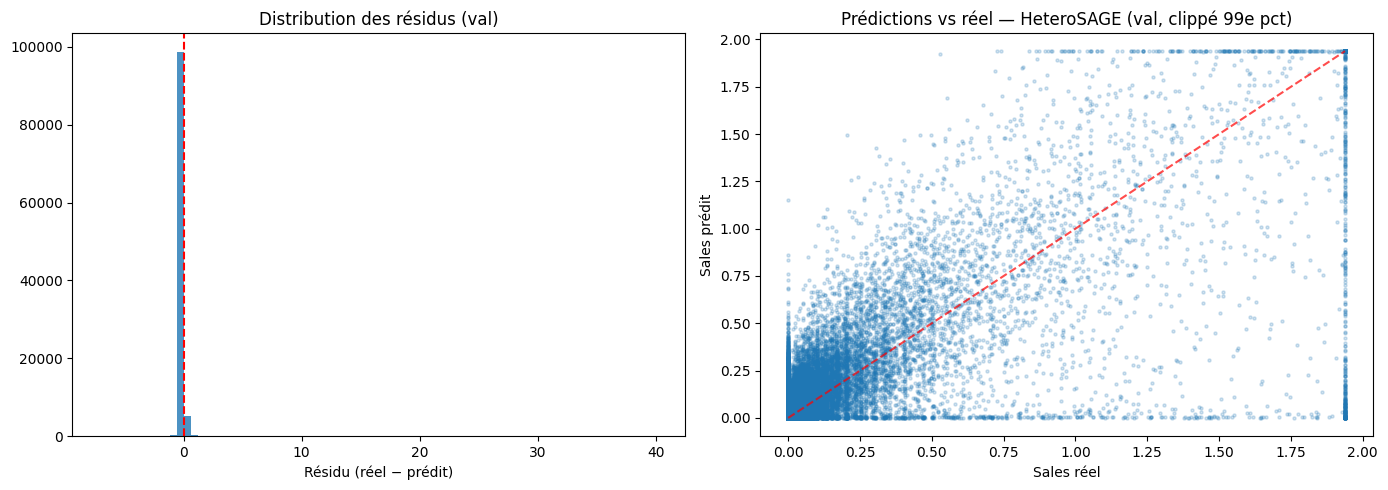

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = y_true_np - y_pred_gnn
axes[0].hist(residuals, bins=80, edgecolor='none', alpha=0.8)
axes[0].axvline(0, color='red', lw=1.5, ls='--')
axes[0].set_title('Distribution des résidus (val)')
axes[0].set_xlabel('Résidu (réel − prédit)')

clip = np.percentile(y_true_np, 99)
axes[1].scatter(np.clip(y_true_np, 0, clip), np.clip(y_pred_gnn, 0, clip), alpha=0.2, s=5)
axes[1].plot([0, clip], [0, clip], 'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — HeteroSAGE (val, clippé 99e pct)')
plt.tight_layout(); plt.show()


## Entraînement : 0 saut vs 2 sauts

On rejoue l'ablation de profondeur principale avec les nouvelles features.
Si les features comportementales customer sont utiles, le delta 0→2 sauts devrait
être positif ou moins négatif qu'avant (ref : Δ = −0.011 avec les features originales).


In [13]:
import json, time, gc, random
from pathlib import Path

RESULTS_DIR = Path('../reports/ablations')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEEDS  = [0, 1, 2]
DEPTHS = [0, 2]

rich_runs = []
for n_layers in DEPTHS:
    for seed in SEEDS:
        r = train_and_eval(n_layers=n_layers, use_temporal=True, use_art_hist=True,
                           seed=seed, epochs=200, patience=20, verbose=(n_layers==2 and seed==0))
        r['experiment'] = 'rich_features'
        rich_runs.append(r)
        print(f"hops={n_layers} seed={seed} | RMSE {r['rmse']:.4f} | "
              f"R2 {r['r2']:.4f} | corr {r['corr']:.3f} | {r['epochs_ran']}ep {r['sec']}s")

out = RESULTS_DIR / 'rich_features_ablation.json'
with open(out, 'w') as f:
    json.dump(rich_runs, f, indent=2)
print(f"\nSauvegarde -> {out}")


hops=0 seed=0 | RMSE 0.4340 | R2 0.5707 | corr 0.756 | 200ep 68.4s


hops=0 seed=1 | RMSE 0.4346 | R2 0.5694 | corr 0.756 | 200ep 68.7s


hops=0 seed=2 | RMSE 0.4334 | R2 0.5717 | corr 0.757 | 200ep 68.7s


  epoch   1 | MSE 0.2564 | Val RMSE 0.6545


  epoch  20 | MSE 0.1666 | Val RMSE 0.5570


...

  epoch 180 | MSE 0.0919 | Val RMSE 0.4430


  epoch 200 | MSE 0.0904 | Val RMSE 0.4425


hops=2 seed=0 | RMSE 0.4424 | R2 0.5537 | corr 0.745 | 200ep 102.6s


hops=2 seed=1 | RMSE 0.4355 | R2 0.5676 | corr 0.755 | 200ep 99.4s


hops=2 seed=2 | RMSE 0.4353 | R2 0.5681 | corr 0.755 | 200ep 102.0s

Sauvegarde -> ../reports/ablations/rich_features_ablation.json


## Synthese et comparaison avec baseline originale

In [14]:
import pandas as pd, numpy as np, json

# Resultats nouveaux
with open(RESULTS_DIR / 'rich_features_ablation.json') as f:
    rich = pd.DataFrame(json.load(f))

# Resultats de reference (originaux, depuis depth_ablation.json)
with open(RESULTS_DIR / 'depth_ablation.json') as f:
    orig = pd.DataFrame(json.load(f))

r_new  = rich.groupby('n_layers')[['rmse', 'r2', 'corr']].agg(['mean', 'std'])
r_orig = orig[orig['n_layers'].isin([0, 2])].groupby('n_layers')[['rmse', 'r2', 'corr']].agg(['mean', 'std'])

print("=== Comparaison features originales vs features enrichies ===")
print(f"\n{'Config':<28} {'RMSE':>10} {'R2':>10} {'corr':>8}")
print('-' * 60)
for n in [0, 2]:
    for label, df in [('orig', r_orig), ('rich', r_new)]:
        if n not in df.index: continue
        row = df.loc[n]
        print(f"hops={n} {label:<22} {row[('rmse','mean')]:.4f}+-{row[('rmse','std')]:.4f}  "
              f"{row[('r2','mean')]:.4f}+-{row[('r2','std')]:.4f}  "
              f"{row[('corr','mean')]:.3f}+-{row[('corr','std')]:.3f}")

print()
for label, df in [('orig', r_orig), ('rich', r_new)]:
    if 0 not in df.index or 2 not in df.index: continue
    delta = df.loc[2, ('r2','mean')] - df.loc[0, ('r2','mean')]
    print(f"Delta R2 (0->2 sauts) [{label}] : {delta:+.4f}")

# Reference LGBM et persistance
print()
print(f"LightGBM      : RMSE 0.4089 | R2 0.6188 (ref)")
print(f"Persistance   : RMSE 0.4323 | R2 0.5739 (ref)")


=== Comparaison features originales vs features enrichies ===

Config                             RMSE         R2     corr
------------------------------------------------------------
hops=0 orig                   0.4320+-0.0015  0.5745+-0.0030  0.759+-0.002
hops=0 rich                   0.4340+-0.0006  0.5706+-0.0012  0.756+-0.001
hops=2 orig                   0.4377+-0.0024  0.5633+-0.0047  0.752+-0.003
hops=2 rich                   0.4377+-0.0041  0.5631+-0.0081  0.752+-0.006

Delta R2 (0->2 sauts) [orig] : -0.0112
Delta R2 (0->2 sauts) [rich] : -0.0075

LightGBM      : RMSE 0.4089 | R2 0.6188 (ref)
Persistance   : RMSE 0.4323 | R2 0.5739 (ref)
